# Ejercicios con Seaborn

`Manuel Avecilla`

---

In [1]:
import seaborn as sns
import pandas as pd

titanic = sns.load_dataset("titanic")

titanic['embarked']=titanic['embarked'].fillna('Unkown')
titanic['embark_town']=titanic['embark_town'].fillna('Unkown')
titanic['deck'] = titanic['deck'].cat.add_categories('Unkown')
titanic['deck']=titanic['deck'].fillna('Unkown')
titanic['age']=titanic['age'].fillna(titanic['age'].median())

Dado el dataset con la información de los pasajeros del titanic que puedes cargar con el código anterior, realiza los siguientes ejercicios (realizando gestión de nulos):

---

**1.** Representa mediante un histograma (utilizando sns.distplot) la tarifa pagada por los pasajeros (fare). Utiliza 20 bins y muestra dos gráficas, una con la estimación de la probabilidad y otra sin ella.

* Para crear dos ejes dentro de un gráfico deberás hacer uso de matplotlib.

/tmp/ipykernel_38331/2296230007.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(titanic['fare'], bins=20, kde=True, ax=axes[0])
/tmp/ipykernel_38331/2296230007.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(titanic['fare'], bins=20, kde=False, ax=axes[1])


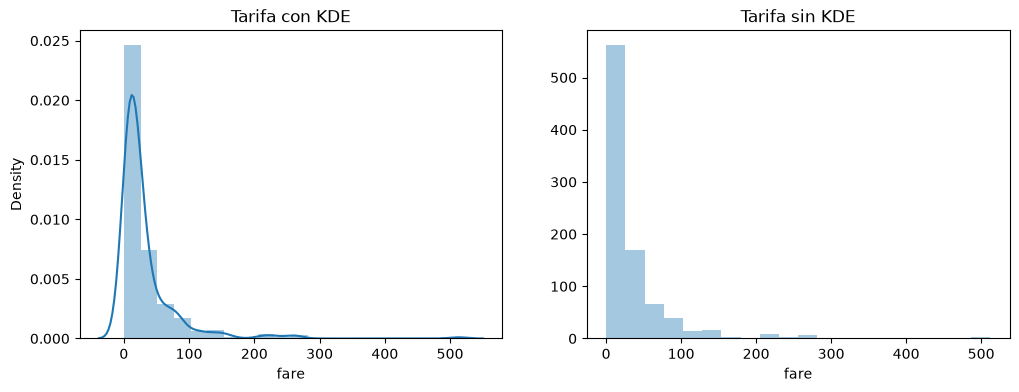

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Con estimación de la probabilidad (KDE)
sns.distplot(titanic['fare'], bins=20, kde=True, ax=axes[0])
axes[0].set_title('Tarifa con KDE')

# Sin estimación de la probabilidad
sns.distplot(titanic['fare'], bins=20, kde=False, ax=axes[1])
axes[1].set_title('Tarifa sin KDE')

plt.show()

**2.** Representa la distribución de edades de los pasajeros con un histograma (utilizando sns.kdeplot). Incluye el parámetro hue para diferenciar por la variable sex.

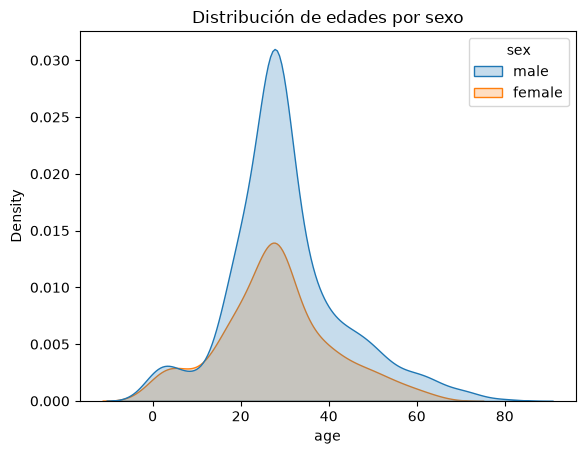

In [3]:
sns.kdeplot(data=titanic, x='age', hue='sex', fill=True)
plt.title('Distribución de edades por sexo')
plt.show()

**3.** Representa la relación entre tarifa y edad.

* Usa un diagrama de dispersión con sns.scatterplot.

* Incluye el parámetro hue para diferenciar por survived y size para escalar los puntos según la cantidad de hermanos/esposos (sibsp).

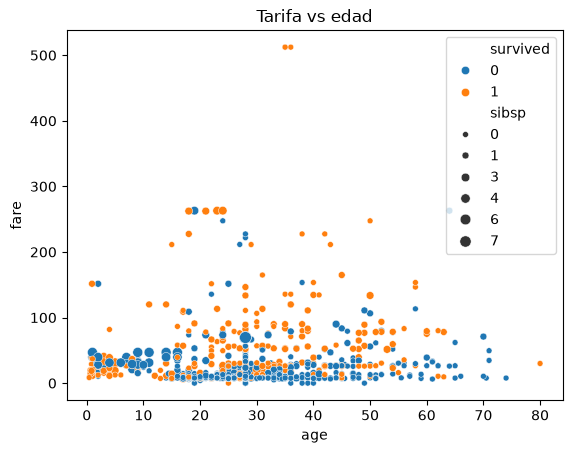

In [4]:
sns.scatterplot(data=titanic, x='age', y='fare', hue='survived', size='sibsp')
plt.title('Tarifa vs edad')
plt.show()

**4.** Representa la distribución de todas las combinaciones binarias de columnas con sns.pairplot.

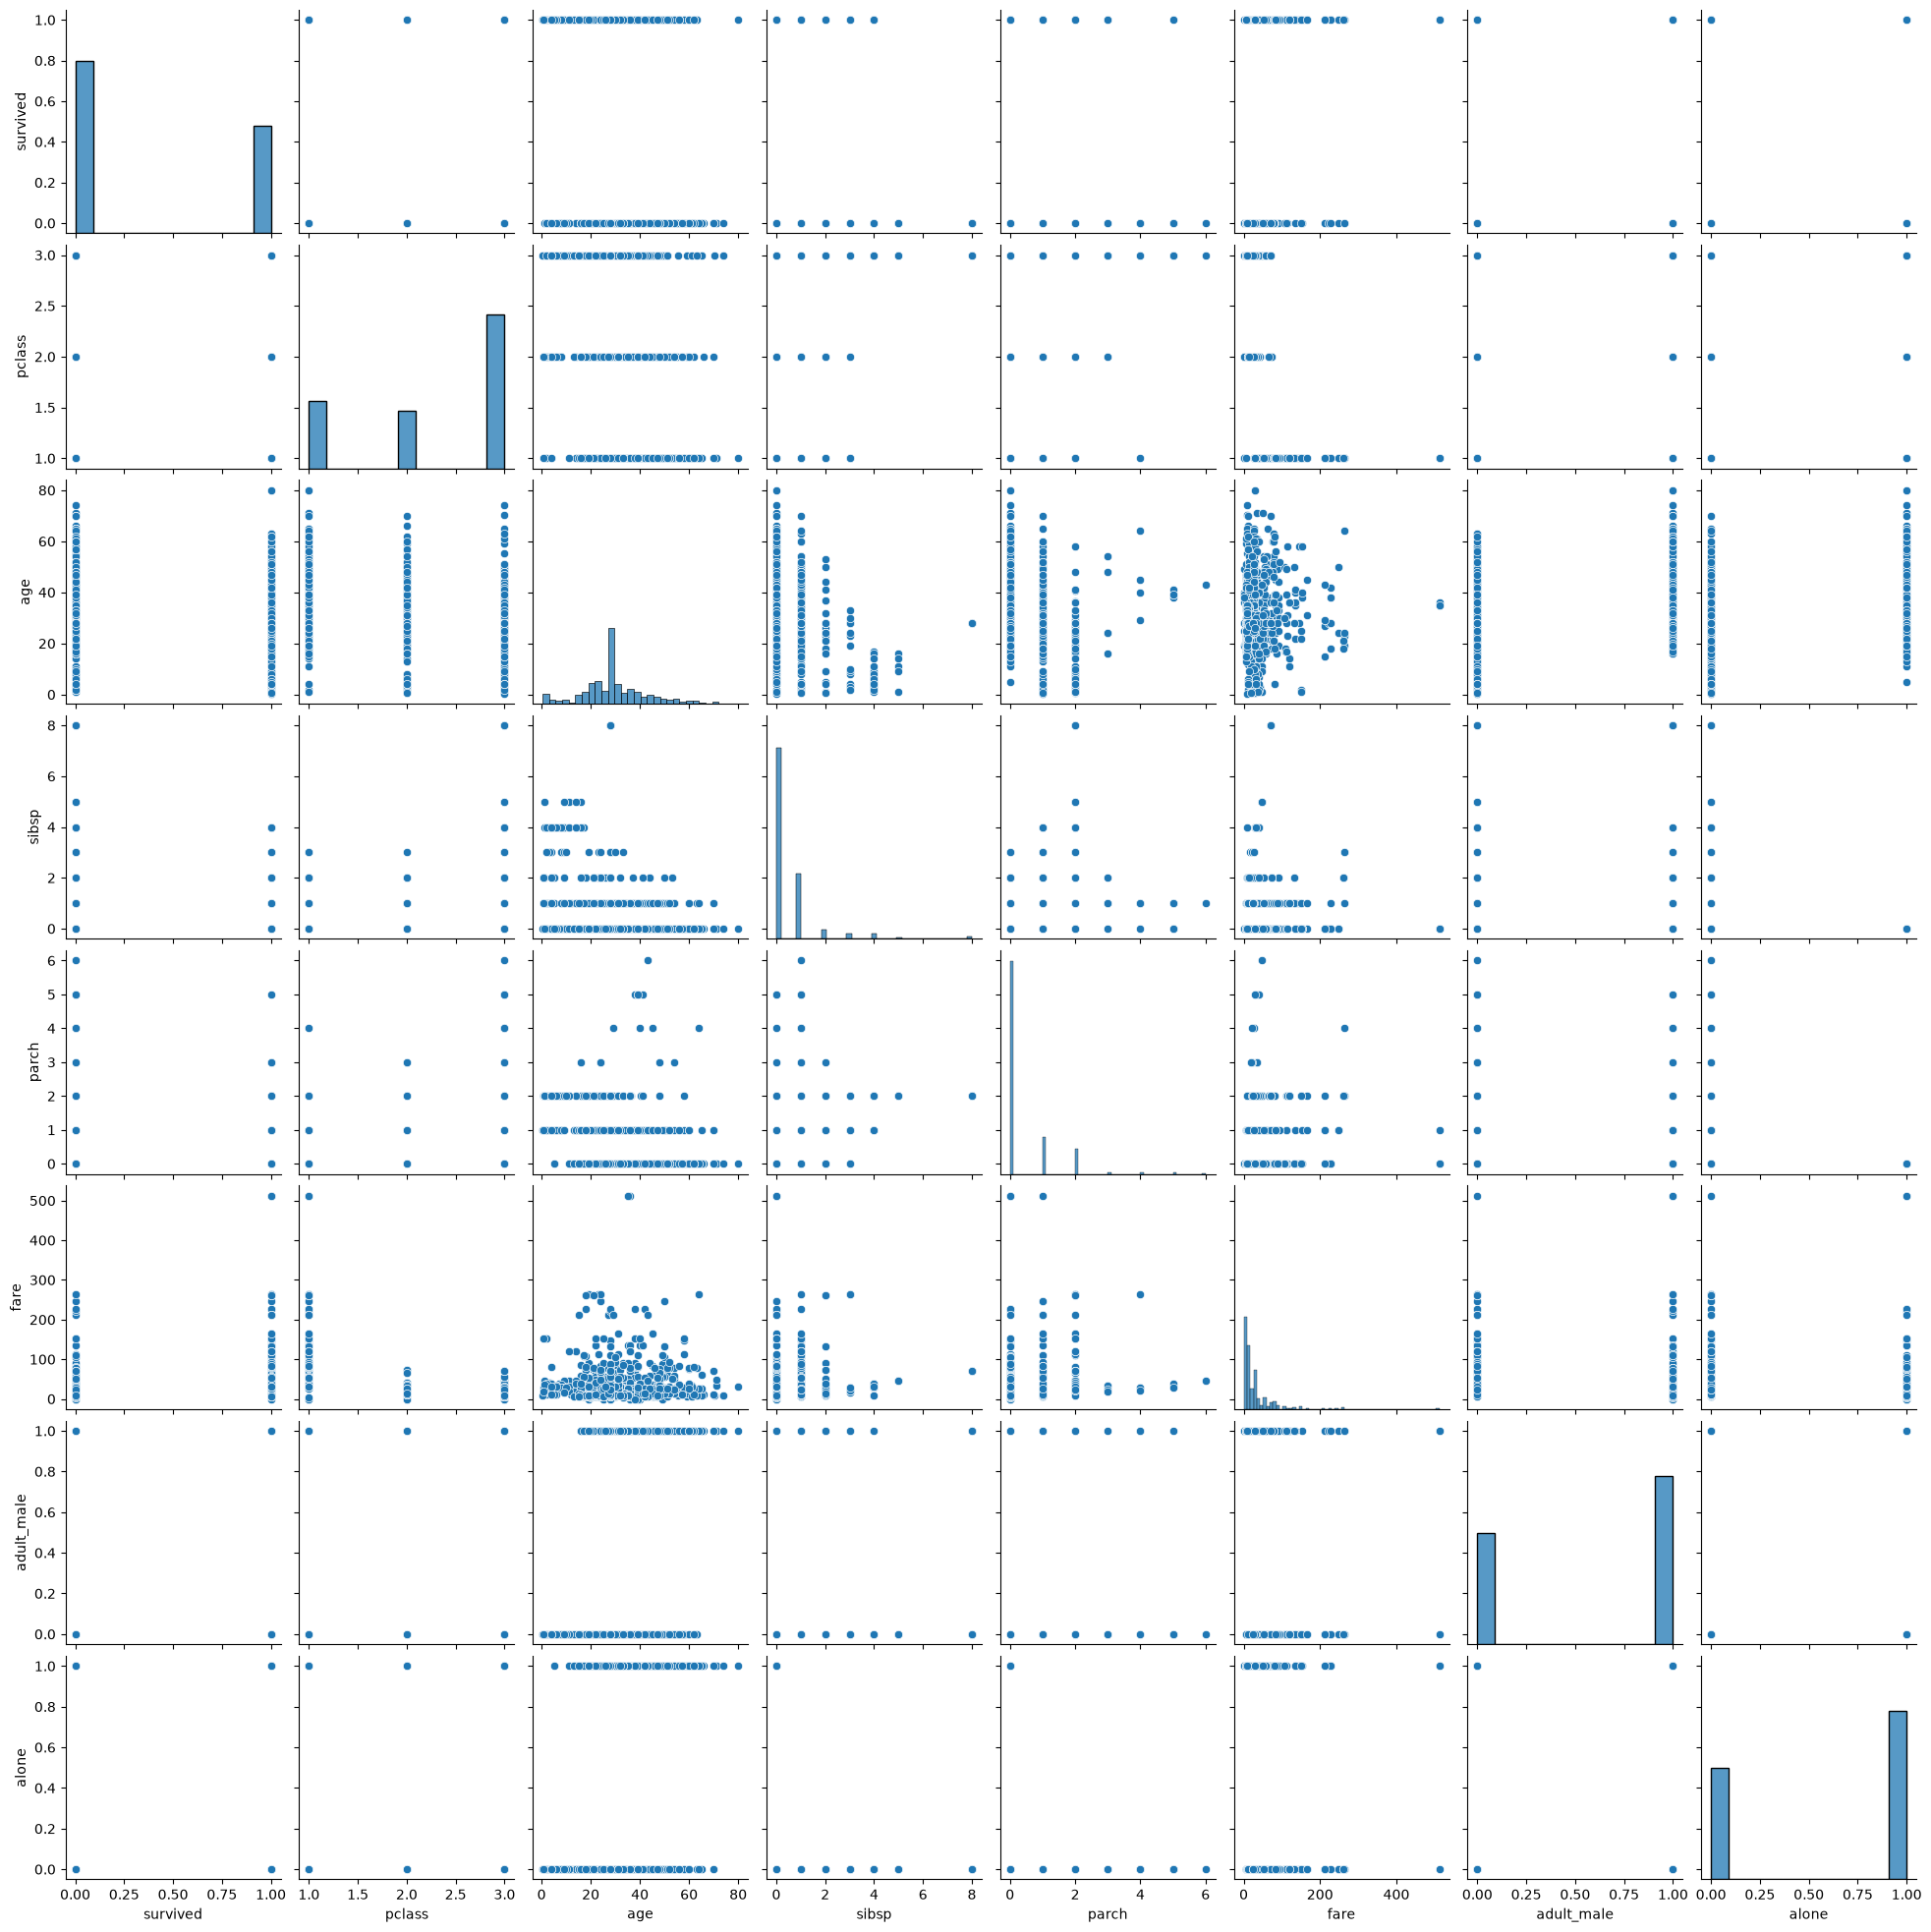

In [5]:
# pairplot solo usa las columnas numéricas
sns.pairplot(titanic)
plt.show()

**5.** Representa las correlaciones del dataset con un mapa de calor usando sns.heatmap.

* Ten en cuenta que la correlación sólo puede trabajar con valores numéricos.

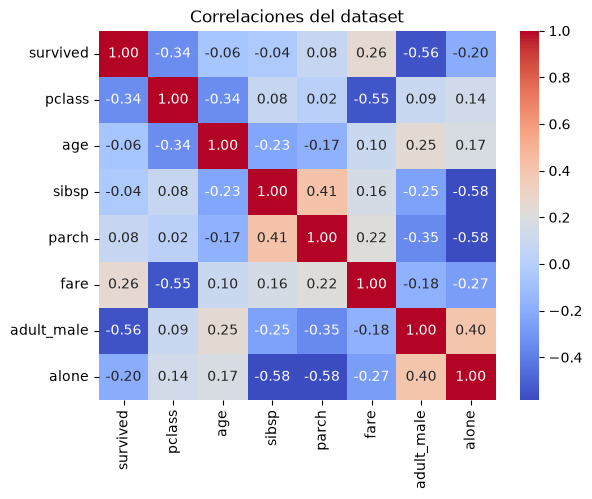

In [6]:
# La correlación solo funciona con columnas numéricas
corr = titanic.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlaciones del dataset')
plt.show()

**6.** Representa la relación entre relación entre tarifa (fare), edad (age), clase (pclass) y tipo de persona (who).

* Usa sns.relplot con las variables seleccionadas.

* Usa el parámetro hue para diferenciar por survived.

* Usa los facets para diferenciar por tipo de persona (who).

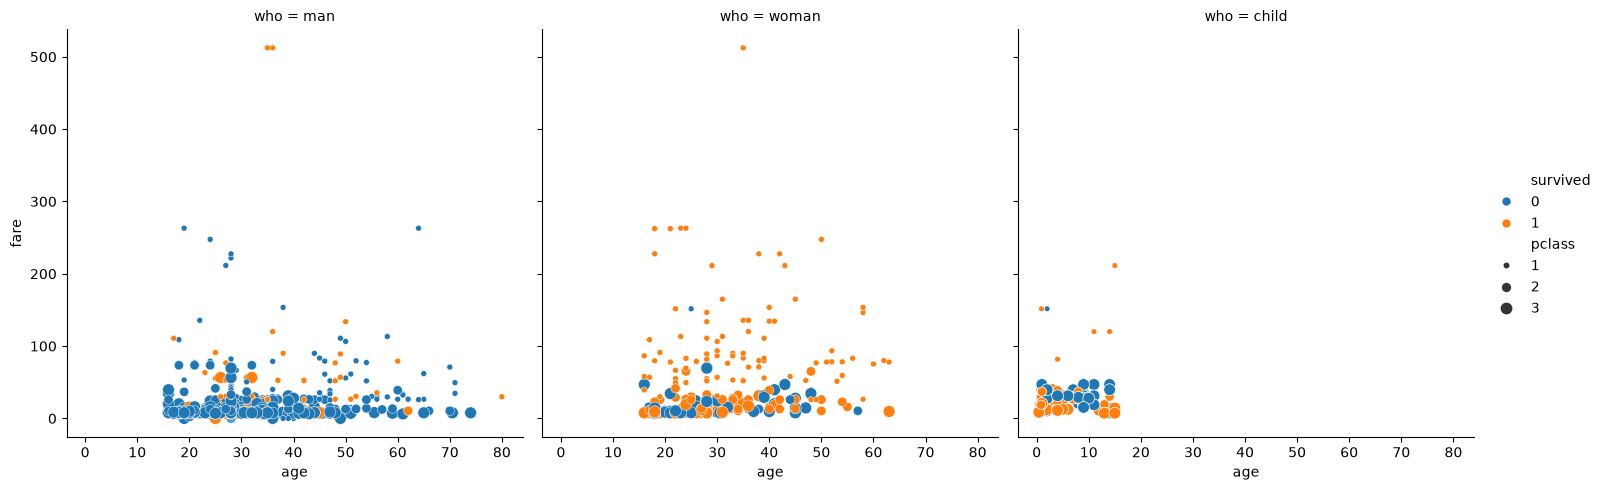

In [7]:
sns.relplot(data=titanic, x='age', y='fare', hue='survived',
            size='pclass', col='who')
plt.show()

**7.** Representa las relación entre tarifa y edad con un sns.jointplot.

* Usa el tipo kde para visualizar las densidades conjuntas y marginales.

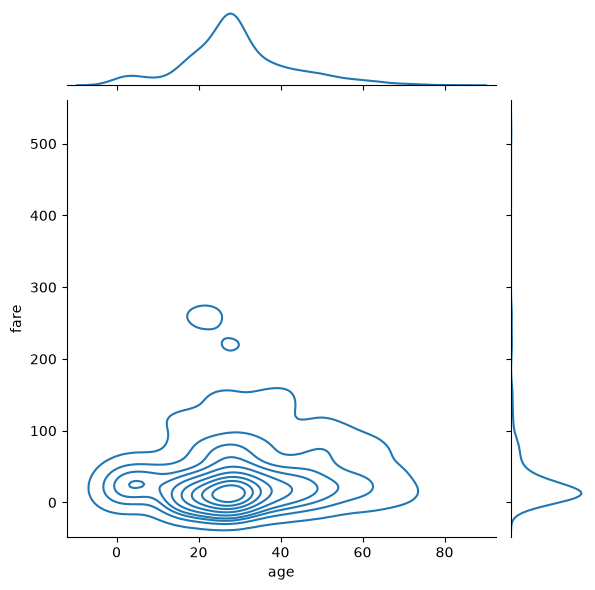

In [8]:
sns.jointplot(data=titanic, x='age', y='fare', kind='kde')
plt.show()

**8.** Representa la edad en función de la clase (pclass)  usando sns.catplot.

* Usa hue para diferenciar por sex.

* Usa los facets para diferenciar por puerto de embarque (embark_town) y si sobrevivió (suvirved).

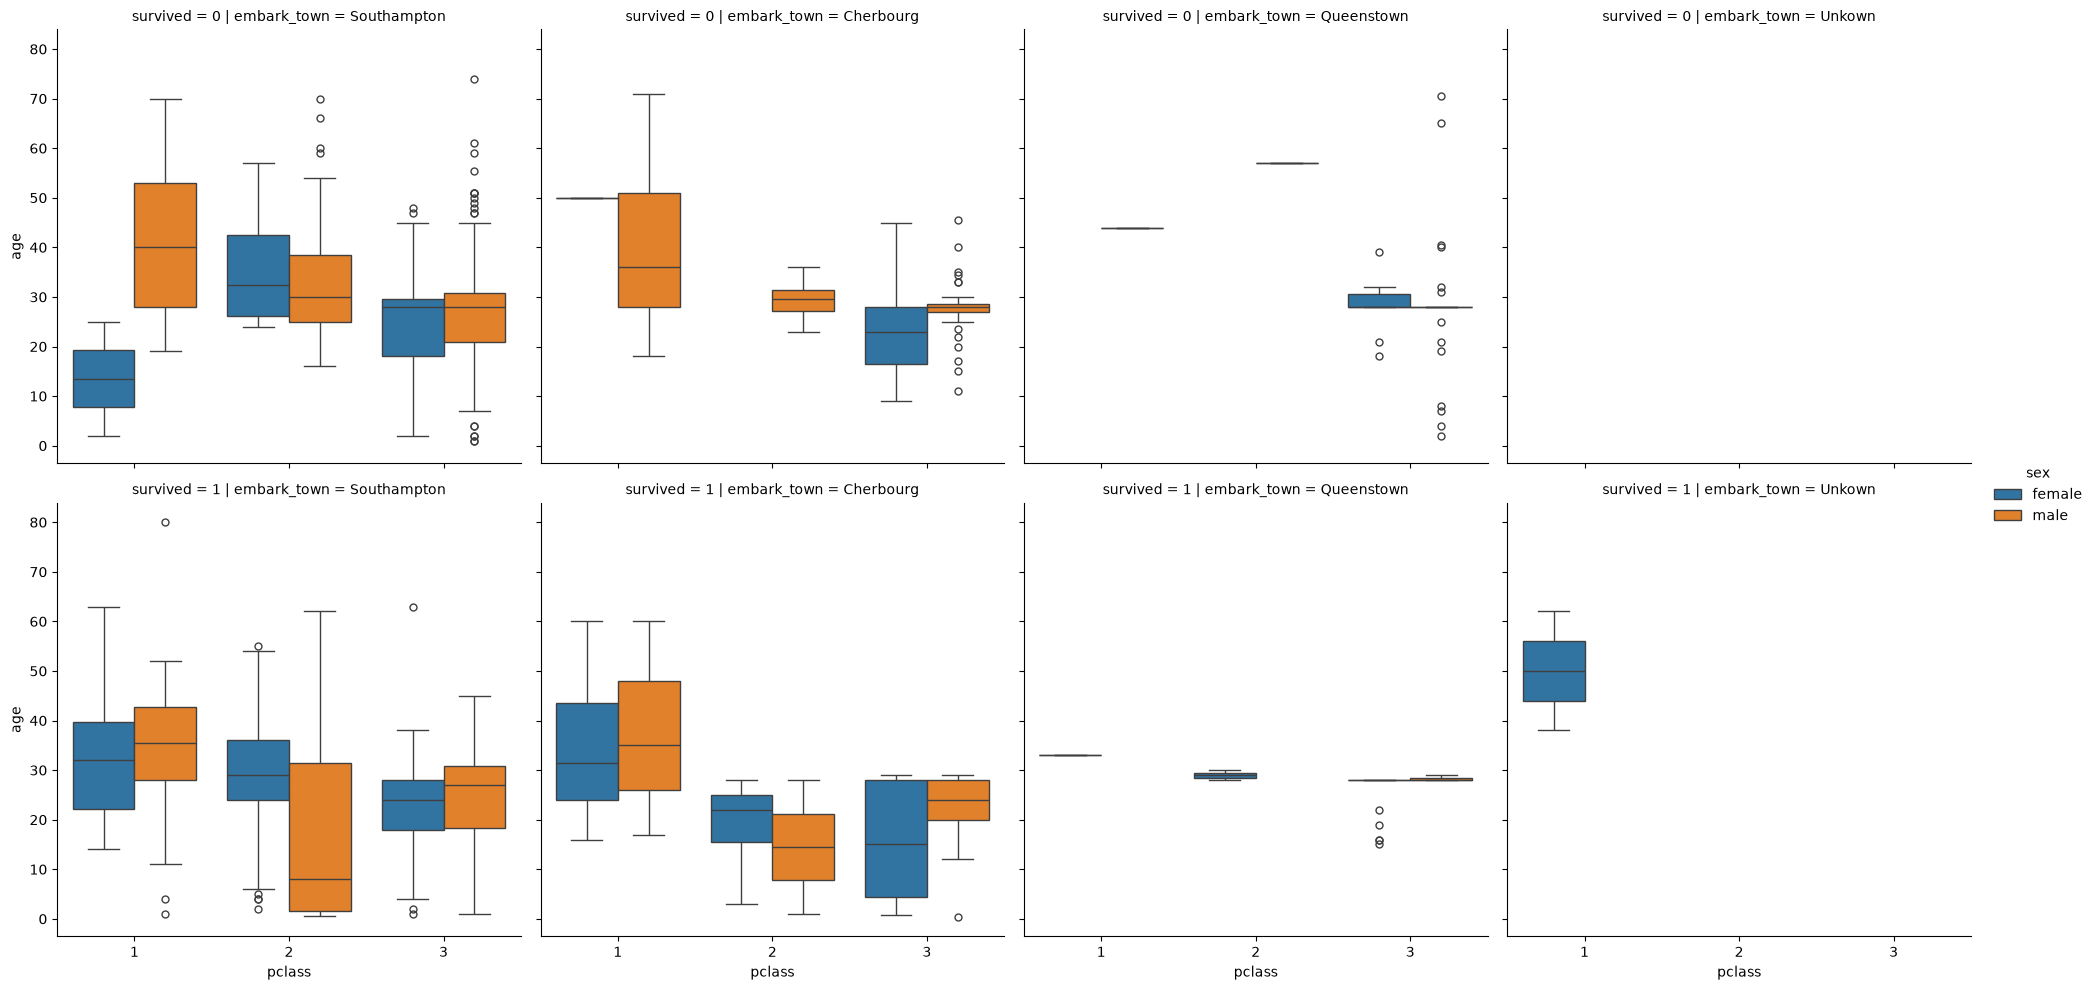

In [9]:
sns.catplot(data=titanic, x='pclass', y='age', hue='sex',
            col='embark_town', row='survived', kind='box')
plt.show()

**9.** Representa el cambio promedio de las tarifas (fare) según la clase utilizando un intervalo de confianza del 90%.

* Usa sns.lineplot para mostrar la relación promedio entre pclass y fare.

* Diferencia por sex con el parámetro hue.

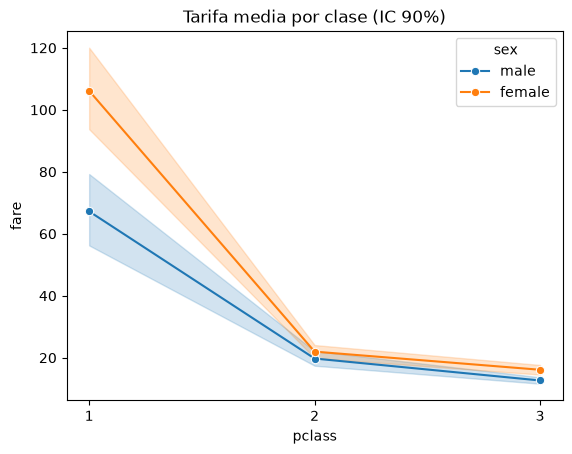

In [10]:
sns.lineplot(data=titanic, x='pclass', y='fare', hue='sex',
             errorbar=('ci', 90), marker='o')
plt.xticks([1, 2, 3])
plt.title('Tarifa media por clase (IC 90%)')
plt.show()

**10.** Utiliza un diagrama de dispersión categórico para comparar la distribución de tarifas (fare) entre clases (pclass).

* Usa sns.stripplot y sns.swarmplot y elige el que mejor transmita la información.

* Usa hue para diferenciar por tipo de persona (who).

/home/manuel/IABD/PIA-MIA/venv/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 7.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/manuel/IABD/PIA-MIA/venv/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 10.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/manuel/IABD/PIA-MIA/venv/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 63.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/manuel/IABD/PIA-MIA/venv/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 11.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/manuel/IABD/PIA-MIA/venv/lib/py

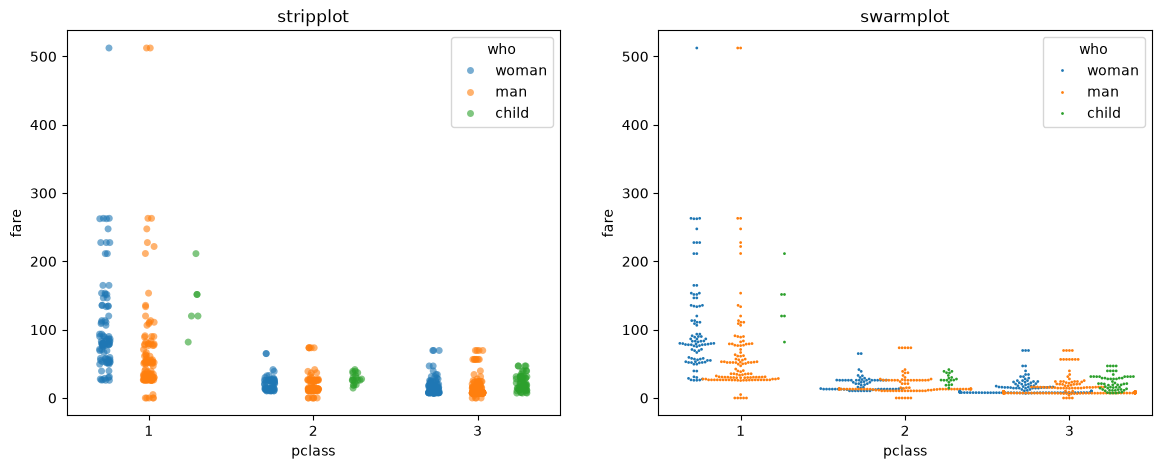

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.stripplot(data=titanic, x='pclass', y='fare', hue='who',
              dodge=True, alpha=0.6, ax=axes[0])
axes[0].set_title('stripplot')

sns.swarmplot(data=titanic, x='pclass', y='fare', hue='who',
              dodge=True, size=2, ax=axes[1])
axes[1].set_title('swarmplot')

plt.show()

# Elegimos stripplot: con casi 900 puntos el swarmplot no puede colocar
# todos los puntos (aparecen avisos) y se ve más saturado.

**11.** Representa la distribución de edades según clase y supervivencia.

* Usa sns.catplot para mostrar la distribución de edades con un diagrama de caja y bigotes.

* Diferencia por survived con el parámetro hue.

* Utiliza los facets para diferenciar por sexo (sex) y tipo de persona(who)

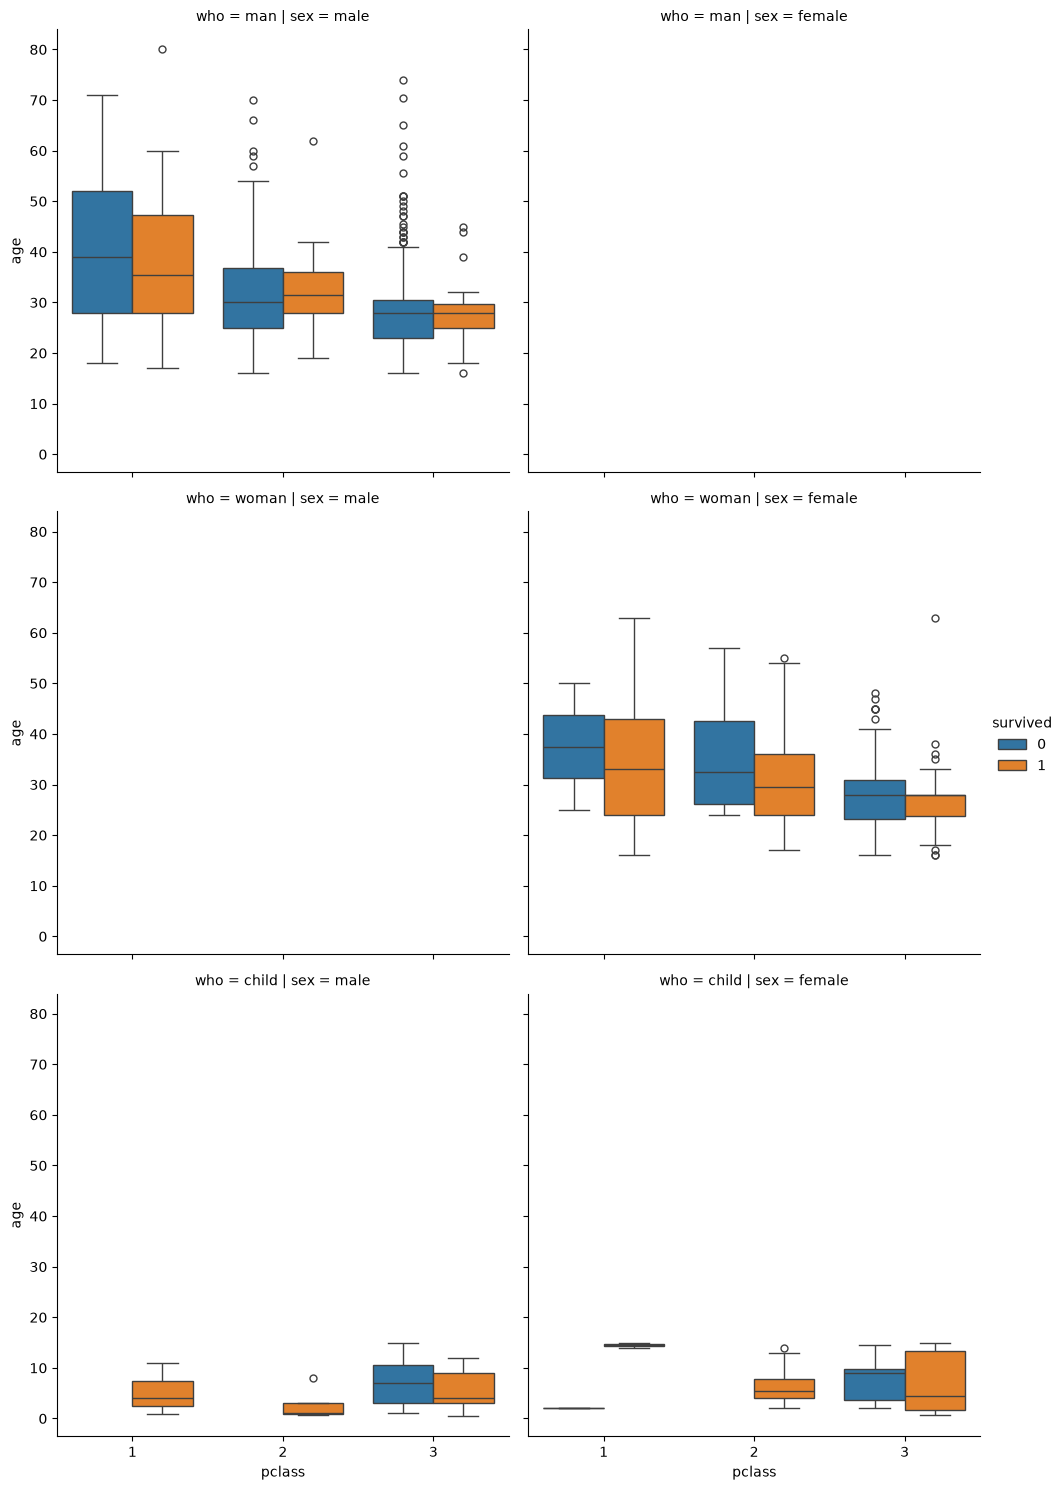

In [12]:
sns.catplot(data=titanic, x='pclass', y='age', hue='survived',
            col='sex', row='who', kind='box')
plt.show()

**12.** Utiliza un diagrama de violín para mostrar las tarifas según clase y sexo.

* Agrega split=True para superponer los datos masculinos y femeninos dentro de cada clase.

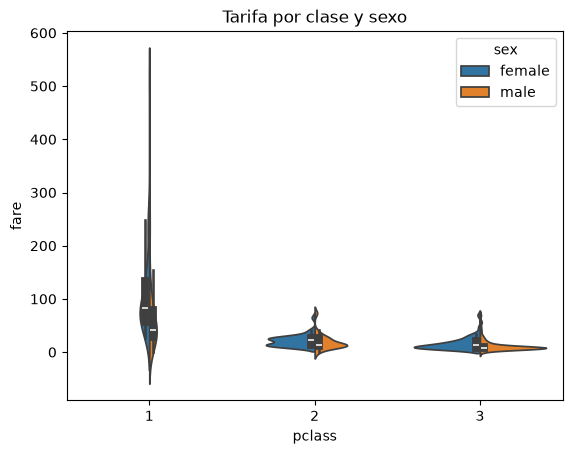

In [13]:
sns.violinplot(data=titanic, x='pclass', y='fare', hue='sex', split=True)
plt.title('Tarifa por clase y sexo')
plt.show()

**13.** Representa el porcentaje de supervivencia por clase y sexo utilizando un diagrama de barras.

* Utiliza los facets para diferenciar por categoría de edad (valores de edad agrupados de 10 en 10). Mostrando como mucho 3 columnas y tantas filas necesites.

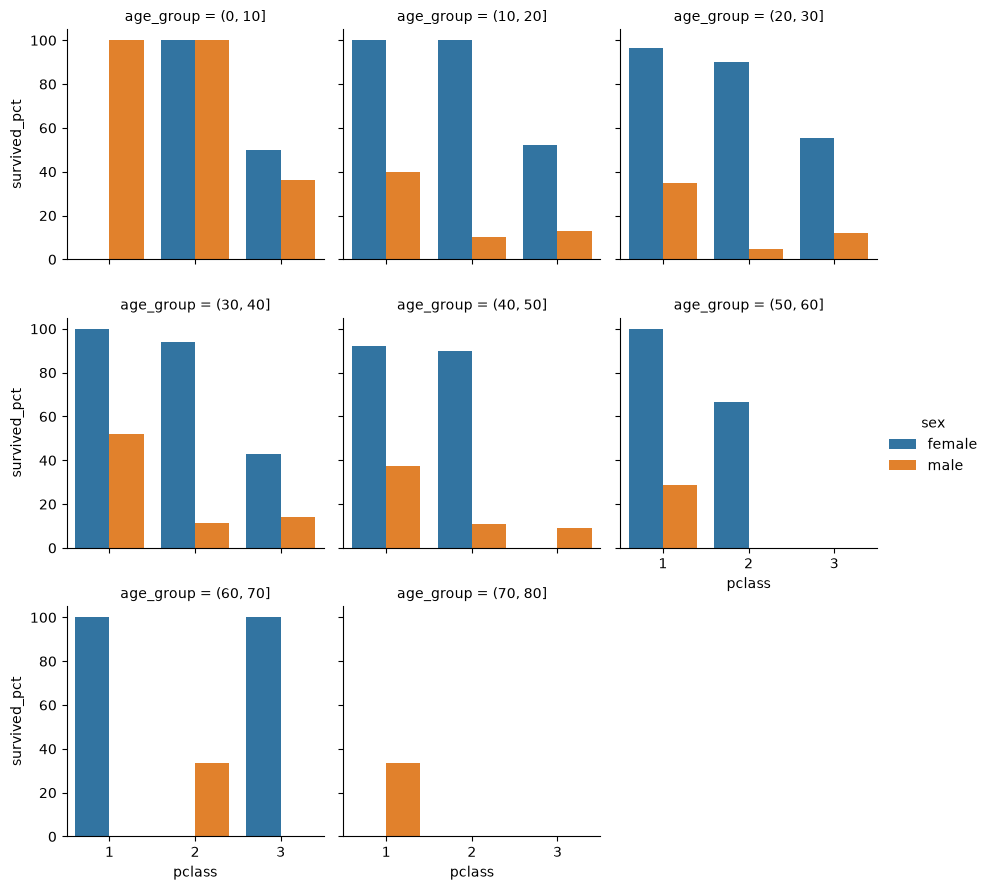

In [14]:
# Agrupamos la edad de 10 en 10 y calculamos la supervivencia en porcentaje
titanic['age_group'] = pd.cut(titanic['age'], bins=range(0, 90, 10))
titanic['survived_pct'] = titanic['survived'] * 100

sns.catplot(data=titanic, x='pclass', y='survived_pct', hue='sex',
            col='age_group', col_wrap=3, kind='bar', errorbar=None,
            height=3)
plt.show()

**14.** Representa una línea de regresión entre la tarifa y la edad.

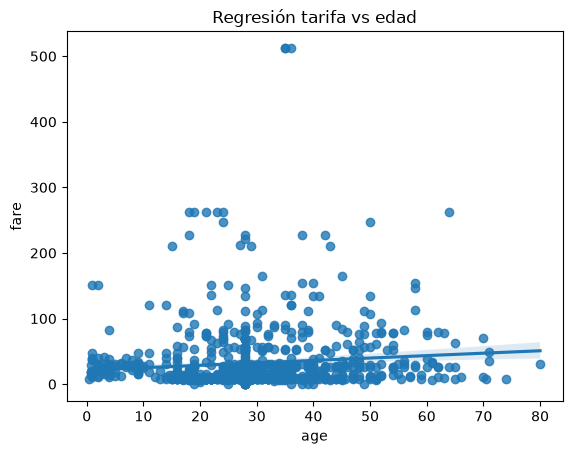

In [15]:
sns.regplot(data=titanic, x='age', y='fare')
plt.title('Regresión tarifa vs edad')
plt.show()

**15.** Representa una línea de regresión entre la tarifa y la edad segmentando por sexo y clase.

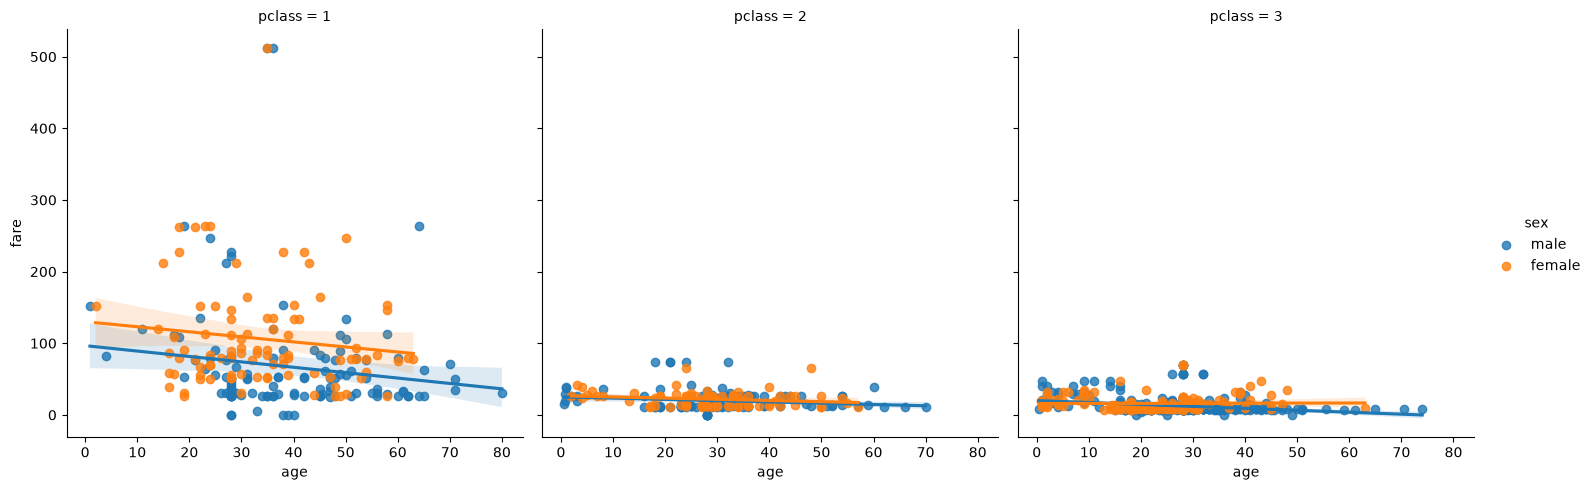

In [16]:
sns.lmplot(data=titanic, x='age', y='fare', hue='sex', col='pclass')
plt.show()